# Demo — Frequency-Domain Separation (SAFE example, not the assignment's own data)
This uses two synthetic tones instead of the whisper/rumble recordings, so it's safe to run
live in a help session without handing out the assignment's solution.

- "Rumble" stand-in: a 60 Hz tone
- "Whistle" stand-in: a 3000 Hz tone

Same pipeline as the assignment: mix -> spectrum -> fftshift -> ideal LPF/HPF -> listen.

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

fs = 16000          # sampling rate (Hz)
duration = 2.0       # seconds
t = np.arange(0, duration, 1/fs)

f_low = 300      # stand-in for "rumble"
f_high = 3000   # stand-in for "whistle"

low_tone = np.sin(2*np.pi*f_low*t)
high_tone = np.sin(2*np.pi*f_high*t)

# peak-normalize each individually (same step the assignment asks for)
low_tone = low_tone / np.max(np.abs(low_tone))
high_tone = high_tone / np.max(np.abs(high_tone))

mixed = low_tone + high_tone
mixed = mixed / np.max(np.abs(mixed))  # peak-normalize the mixture

print("Original Low Tone (300 Hz):")
display(Audio(low_tone, rate=fs))
print("Original High Tone (3000 Hz):")
display(Audio(high_tone, rate=fs))
print("Mixed:")
display(Audio(mixed, rate=fs))

Original Low Tone (300 Hz):


Original High Tone (3000 Hz):


Mixed:


## 1. Time domain: can you tell there are two tones just from this plot?

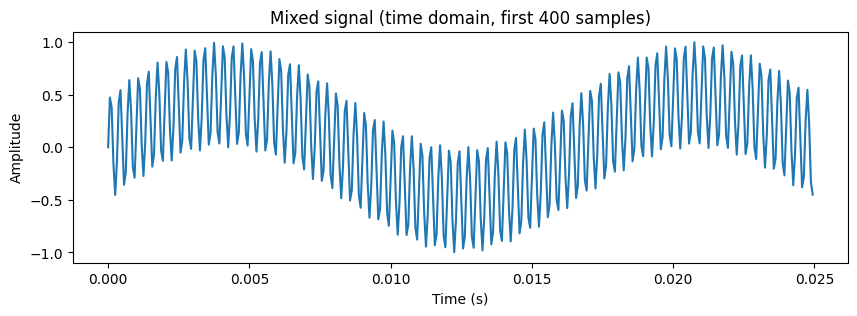

In [4]:
plt.figure(figsize=(10,3))
plt.plot(t[:400], mixed[:400])
plt.title("Mixed signal (time domain, first 400 samples)")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.show()

## 2. Raw FFT (unshifted) — note the wrap-around bin ordering

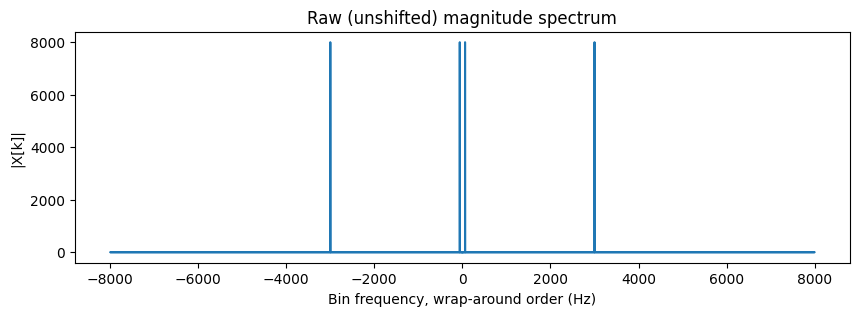

In [5]:
X = np.fft.fft(mixed)
freqs = np.fft.fftfreq(len(mixed), d=1/fs)

plt.figure(figsize=(10,3))
plt.plot(freqs, np.abs(X))
plt.title("Raw (unshifted) magnitude spectrum")
plt.xlabel("Bin frequency, wrap-around order (Hz)")
plt.ylabel("|X[k]|")
plt.show()

## 3. fftshift both X and freqs together

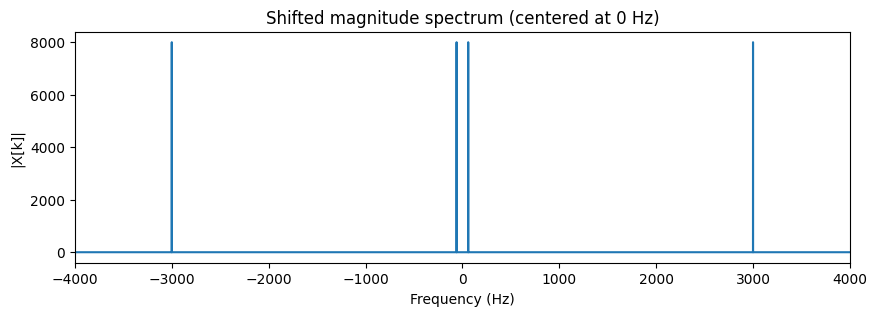

In [6]:
X_shifted = np.fft.fftshift(X)
freqs_shifted = np.fft.fftshift(freqs)

plt.figure(figsize=(10,3))
plt.plot(freqs_shifted, np.abs(X_shifted))
plt.title("Shifted magnitude spectrum (centered at 0 Hz)")
plt.xlabel("Frequency (Hz)")
plt.ylabel("|X[k]|")
plt.xlim(-4000, 4000)
plt.show()

# Discussion prompt: what would this look like if we'd shifted only X or only freqs?

## 4. Ideal LPF and HPF — pick a cutoff BETWEEN the two demo tones
Here 60 Hz and 3000 Hz are far apart, so almost any cutoff between them works —
good for illustrating the concept without needing a carefully "optimal" choice.

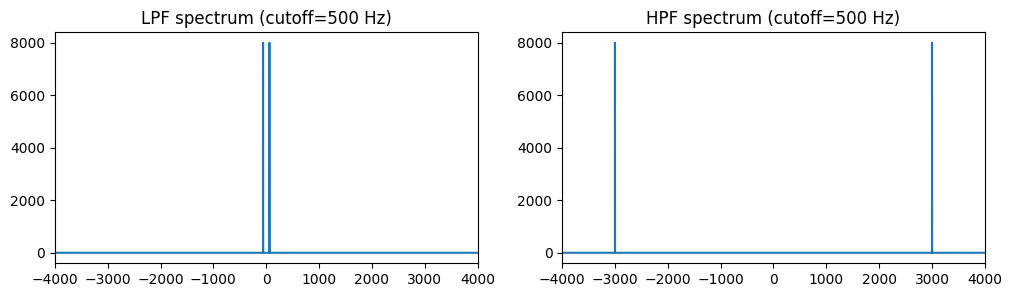

In [7]:
cutoff = 500  # illustrative only — sits between 60 Hz and 3000 Hz

mask_lpf = np.abs(freqs_shifted) <= cutoff
mask_hpf = np.abs(freqs_shifted) >= cutoff

X_lpf = X_shifted * mask_lpf
X_hpf = X_shifted * mask_hpf

# undo the shift before inverse FFT
lpf_out = np.fft.ifft(np.fft.ifftshift(X_lpf)).real
hpf_out = np.fft.ifft(np.fft.ifftshift(X_hpf)).real

fig, axs = plt.subplots(1, 2, figsize=(12,3))
axs[0].plot(freqs_shifted, np.abs(X_lpf))
axs[0].set_title(f"LPF spectrum (cutoff={cutoff} Hz)")
axs[0].set_xlim(-4000,4000)
axs[1].plot(freqs_shifted, np.abs(X_hpf))
axs[1].set_title(f"HPF spectrum (cutoff={cutoff} Hz)")
axs[1].set_xlim(-4000,4000)
plt.show()

## 5. Listen — LPF should sound like the low tone, HPF like the high tone

In [8]:
print("Mixed:")
display(Audio(mixed, rate=fs))
print("Low-pass filtered (should sound like the 300 Hz tone):")
display(Audio(lpf_out, rate=fs))
print("High-pass filtered (should sound like the 3000 Hz tone):")
display(Audio(hpf_out, rate=fs))

Mixed:


Low-pass filtered (should sound like the 60 Hz tone):


High-pass filtered (should sound like the 3000 Hz tone):


## 6. Zoom in on an edge to see ringing (Gibbs phenomenon)
Ideal brick-wall filters are non-causal / infinitely sharp — this shows up as
small oscillations near sharp transitions in the time-domain output.

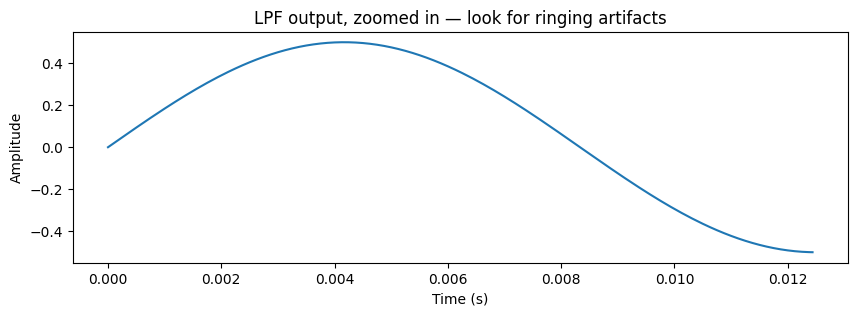

In [9]:
plt.figure(figsize=(10,3))
plt.plot(t[:200], lpf_out[:200])
plt.title("LPF output, zoomed in — look for ringing artifacts")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.show()